# L6: How are Tabular Foundation Models built?

In this lesson, you will build and pretrain a miniature tabular foundation model from scratch (following [nanoTabPFN](https://github.com/automl/nanotabpfn)) to see how in-context learning works under the hood. You will implement the full pretraining pipeline in three parts, and then explore how a richer synthetic prior and a larger model improve predictions:

1. **The prior** – sample new synthetic classification datasets on the fly during pretraining.
2. **The model** – build a transformer architecture that attends across both the columns (features) and the rows (datapoints) of a table.
3. **The pretraining loop** – train the model to predict the labels of unlabeled test rows given a context of labeled training rows.

Plotting and evaluation helpers live in `helper.py`.

Recall the diagram we saw for TabPFN inference: ![TabPFN inference phase](TabPFN-inference-phase.jpeg)

Recall the diagram we saw for TabPFN pretraining: ![TabPFN pretraining phase](TabPFN-pretraining-phase.jpeg)

## 0. Setup

Import PyTorch and the evaluation and plotting utilities from `helper.py`, and set a random seed for reproducibility.

In [1]:
import importlib.util

required = ("torch", "numpy", "sklearn", "matplotlib")
if not all(importlib.util.find_spec(package) for package in required):
    %pip install -q torch numpy scikit-learn matplotlib

In [2]:
import time
import torch
import torch.nn.functional as F
from torch import nn

from helper import (
    compare_with_baseline, device, evaluate_model,
    plot_predictions, plot_prior_samples,
)

torch.manual_seed(42)

## 1. The prior: generating the datasets to pretrain on

Sample synthetic tables with 50 rows each, split randomly into train and test rows. Start with a simple linear prior: a random boundary line $f(x_1) = a + b x_1$ with $a, b \sim \mathcal{N}(0, 1)$. Draw $x_1 \sim \mathcal{N}(0, 1)$ and $x_2 \sim f(x_1) + \mathcal{N}(0, 1)$; the label is `1` if the point lies above the line and `0` below it, with a little noise near the boundary.

In [3]:
def sample_from_prior(batch_size, num_rows=50, noise_std=0.1):
    '''A batch of synthetic tables with two features x1 and x2:
    class 1 above a random boundary line, class 0 below it.'''
    # boundary x2 = a + b*x1, one per table
    a = torch.randn(batch_size, 1)  # intercept ~ N(0, 1)
    b = torch.randn(batch_size, 1)  # slope ~ N(0, 1)
    boundary = lambda t: a + b * t
    # points scattered around the boundary
    x1 = torch.randn(batch_size, num_rows)
    x2 = boundary(x1) + torch.randn(batch_size, num_rows)
    # class 1 above the boundary, class 0 below (slightly noisy)
    noise = noise_std * torch.randn(batch_size, num_rows)
    y = (x2 + noise > boundary(x1)).float()
    # the first n_train rows are labeled, the model predicts the rest
    n_train = torch.randint(10, num_rows - 2, ()).item()
    # the boundary is returned only for plotting
    return torch.stack([x1, x2], dim=-1), y, n_train, boundary

Sample 4 synthetic tables from the linear prior and plot their points alongside each table's true decision boundary (dashed line).

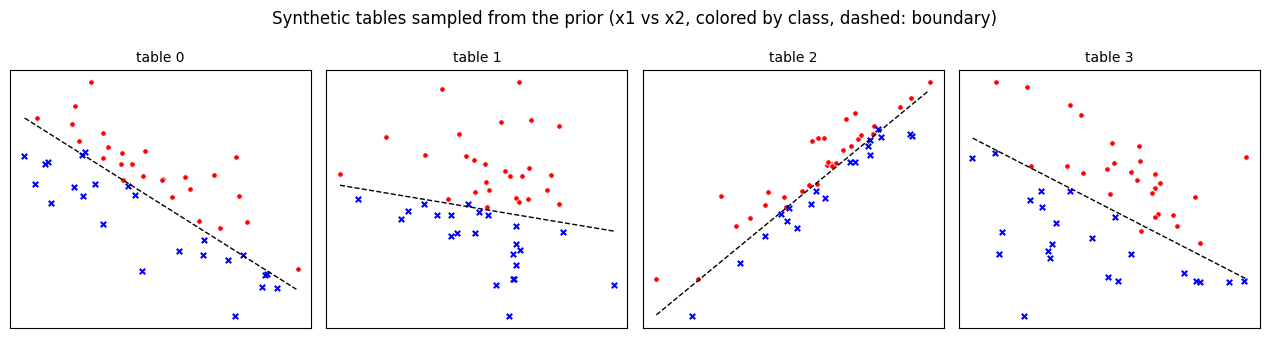

In [4]:
x, y, n_train, boundary = sample_from_prior(4)
plot_prior_samples(x, y, boundary)

## 2. The model: a transformer over table cells

![nanoTabPFN architecture](nanotabpfn_architecture.jpeg)

① -> ② Every cell of the table becomes a vector, so a batch of tables is a tensor of shape `(batch, rows, columns, embedding)`.
The label is appended as one more column: classes 0 and 1 enter the model as $-1$ and $+1$, so that 0 can mean "unknown" for the rows we want to predict.

③ Each layer applies attention in **two directions**:

* **between features** – within a row, cells attend to each other,
* **between datapoints** – within a column, every row attends to the **labeled** rows.

④ The output for each test row is two logits, one per class. Their softmax is the predicted probability of each class, to quantify model uncertainty.

In [5]:
class TransformerLayer(nn.Module):
    '''Attention between features (within a row), attention between
    datapoints (within a column), then an MLP.'''

    def __init__(self, emb, heads):
        super().__init__()
        self.attn_features = nn.MultiheadAttention(
            emb, heads, batch_first=True)
        self.attn_datapoints = nn.MultiheadAttention(
            emb, heads, batch_first=True)
        self.mlp = nn.Sequential(
            nn.Linear(emb, 4 * emb), nn.GELU(), nn.Linear(4 * emb, emb))
        self.norm1 = nn.LayerNorm(emb)
        self.norm2 = nn.LayerNorm(emb)
        self.norm3 = nn.LayerNorm(emb)

    def forward(self, h, n_train):
        B, R, C, E = h.shape  # (batch, rows, columns, embedding)
        # self-attention over the features of each row:
        # fold the row dimension into the batch dimension
        h = h.reshape(B * R, C, E)
        h = self.norm1(h + self.attn_features(h, h, h)[0])
        h = h.reshape(B, R, C, E)
        # attention over the rows of each column:
        # fold the column dimension into the batch dimension;
        # all rows attend to the labeled rows only
        h = h.transpose(1, 2).reshape(B * C, R, E)
        labeled = h[:, :n_train]
        h = self.norm2(h + self.attn_datapoints(h, labeled, labeled)[0])
        h = h.reshape(B, C, R, E).transpose(1, 2)
        return self.norm3(h + self.mlp(h))

In [6]:
class NanoTabPFN(nn.Module):
    def __init__(self, emb, layers, heads=4, num_classes=2):
        super().__init__()
        self.x_encoder = nn.Linear(1, emb)  # embeds each feature cell
        self.y_encoder = nn.Linear(1, emb)  # embeds each label cell
        self.layers = nn.ModuleList(
            [TransformerLayer(emb, heads) for _ in range(layers)])
        self.decoder = nn.Sequential(
            nn.Linear(emb, 4 * emb), nn.GELU(),
            nn.Linear(4 * emb, num_classes))

    def forward(self, x_train, y_train, x_test):
        # x_train: (B, n_train, features), y_train: (B, n_train),
        # x_test: (B, n_test, features)
        n_train = x_train.shape[1]
        # standardize each feature using the labeled rows
        mean = x_train.mean(1, keepdim=True)
        std = x_train.std(1, keepdim=True)
        x = torch.cat([x_train, x_test], dim=1)  # (B, rows, features)
        x = (x - mean) / (std + 1e-8)
        # classes 0 / 1 enter as -1 / +1; unknown test labels as 0
        y = F.pad(2 * y_train - 1, (0, x_test.shape[1]))
        # embed every cell (one number) as a vector of length emb
        x_emb = self.x_encoder(x.unsqueeze(-1))  # (B, rows, features, emb)
        # the label column: (B, rows, 1, emb)
        y_emb = self.y_encoder(y.unsqueeze(-1)).unsqueeze(2)
        h = torch.cat([x_emb, y_emb], dim=2)  # the label: one more column
        for layer in self.layers:
            h = layer(h, n_train)  # (B, rows, features + 1, emb)
        # class logits from the label cell of every test row
        return self.decoder(h[:, n_train:, -1])

## 3. The pretraining loop

Every step in pretraining draws 32 fresh tables, gives the model the labeled rows, and scores its predicted class probabilities on the unlabeled rows with cross-entropy. Minimizing this loss *is* learning to predict in context. The learning rate decays to zero on a cosine schedule, and every 10% of the steps you check accuracy on three test datasets the model never trained on.

In [7]:
def train(model, num_steps, lr, batch_size=32):
    model = model.to(device)  # run on the GPU if there is one
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_steps)
    t0 = time.time()
    for step in range(1, num_steps + 1):
        # fresh synthetic tables every step
        x, y, n_train, _ = sample_from_prior(batch_size)
        x, y = x.to(device), y.to(device)
        # split into labeled (train) and unlabeled (test) rows
        x_train, x_test = x[:, :n_train], x[:, n_train:]
        y_train, y_test = y[:, :n_train], y[:, n_train:]
        logits = model(x_train, y_train, x_test)
        # only the unlabeled rows are scored
        loss = F.cross_entropy(
            logits.reshape(-1, 2), y_test.reshape(-1).long())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        if step % (num_steps // 10) == 0:
            seconds = time.time() - t0
            acc = evaluate_model(model)
            print(f"step {step:4d} | {seconds:5.1f}s | "
                  f"loss {loss.item():6.3f} | test accuracy {acc:.3f}")
    return model

### A first, fast run

A small model (48-dimensional embeddings, 2 layers) pretrained for 750 steps: about 10 seconds on a GPU or Apple Silicon.

In [8]:
small_lines = train(
    NanoTabPFN(emb=48, layers=2), num_steps=750, lr=1e-3)

step   75 |   2.2s | loss  0.275 | test accuracy 0.797
step  150 |   3.9s | loss  0.137 | test accuracy 0.795
step  225 |   5.4s | loss  0.195 | test accuracy 0.807
step  300 |   7.0s | loss  0.160 | test accuracy 0.805
step  375 |   8.6s | loss  0.127 | test accuracy 0.808
step  450 |  10.2s | loss  0.198 | test accuracy 0.800
step  525 |  11.8s | loss  0.128 | test accuracy 0.790
step  600 |  13.4s | loss  0.263 | test accuracy 0.797
step  675 |  14.9s | loss  0.183 | test accuracy 0.797
step  750 |  16.5s | loss  0.189 | test accuracy 0.800


### A simple evaluation on three datasets

Evaluate the model on three test datasets with different boundaries: a straight **line**, a slow **sine wave**, and a **sine + fast wave**. Notice that this first model has only seen data from straight lines during pretraining.

The pretrained model receives 40 labeled points (red dots and blue crosses) as context; the background shading shows its predicted probability everywhere else: red for class 1, blue for class 0, and white where the model is unsure.

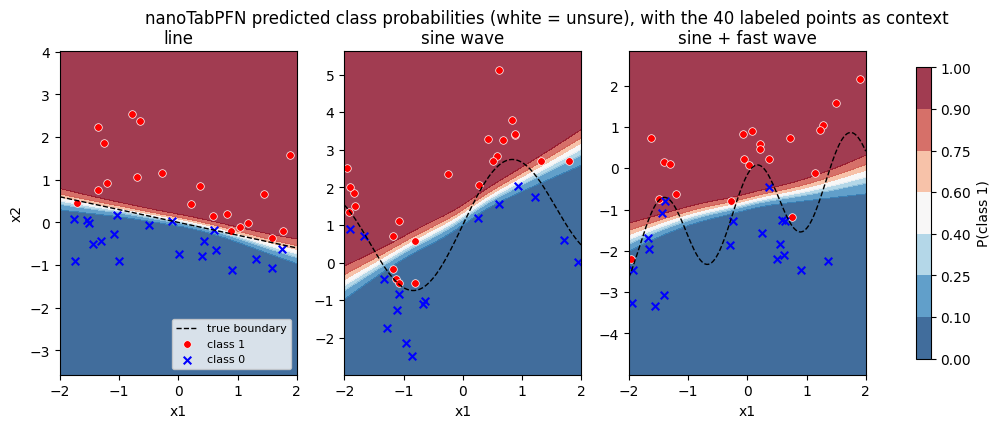

In [9]:
plot_predictions(small_lines)

### Quantitative evaluation

Compare the pretrained model's test accuracy against two classical baselines—logistic regression and a random forest—fitted directly on the same 40 labeled points.

In [10]:
compare_with_baseline({"small, lines prior": small_lines})

accuracy               line   sine wave   sine + fast wave   mean
-----------------------------------------------------------------
small, lines prior    0.955       0.685              0.760  0.800
logistic regression   0.955       0.705              0.760  0.807
random forest         0.925       0.775              0.745  0.815


## 4. A richer prior

Now make the boundary functions more expressive by adding a sine wave on top of the line, with amplitude $A \sim \mathcal{U}(0, 2)$, frequency $\omega \sim \mathcal{U}(0.5, 5)$, and phase $\varphi \sim \mathcal{U}(0, 2\pi)$. The new boundary is:

$$f(x_1) = a + b x_1 + A \sin(\omega x_1 + \varphi)$$

In [11]:
def sample_from_prior(batch_size, num_rows=50, noise_std=0.1):
    '''A batch of synthetic tables with two features x1 and x2:
    class 1 above a random boundary curve, class 0 below it.'''
    # boundary x2 = a + b*x1 + A*sin(w*x1 + phi), one per table
    a = torch.randn(batch_size, 1)                  # intercept ~ N(0, 1)
    b = torch.randn(batch_size, 1)                  # slope ~ N(0, 1)
    amp = 2 * torch.rand(batch_size, 1)             # amplitude ~ U(0, 2)
    w = 0.5 + 4.5 * torch.rand(batch_size, 1)       # frequency ~ U(0.5, 5)
    phi = 2 * torch.pi * torch.rand(batch_size, 1)  # phase ~ U(0, 2 pi)
    boundary = lambda t: a + b * t + amp * torch.sin(w * t + phi)
    # points scattered around the boundary
    x1 = torch.randn(batch_size, num_rows)
    x2 = boundary(x1) + torch.randn(batch_size, num_rows)
    # class 1 above the boundary, class 0 below (slightly noisy)
    noise = noise_std * torch.randn(batch_size, num_rows)
    y = (x2 + noise > boundary(x1)).float()
    # the first n_train rows are labeled, the model predicts the rest
    n_train = torch.randint(10, num_rows - 2, ()).item()
    # the boundary is returned only for plotting
    return torch.stack([x1, x2], dim=-1), y, n_train, boundary

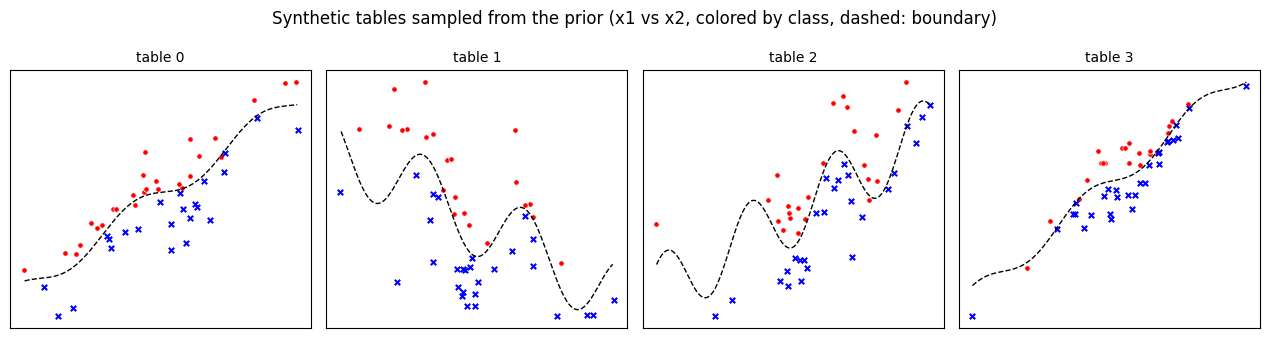

In [12]:
x, y, n_train, boundary = sample_from_prior(4)
plot_prior_samples(x, y, boundary)

### A run with the richer prior

Visualize 4 synthetic tables drawn from this new wave prior, and then pretrain a fresh small model (`emb=48, layers=2`) for 750 steps using the exact same architecture and training loop.

In [13]:
# The same small model and pretraining run, now on the richer prior.
small = train(NanoTabPFN(emb=48, layers=2), num_steps=750, lr=1e-3)

step   75 |   1.7s | loss  0.555 | test accuracy 0.650
step  150 |   3.3s | loss  0.387 | test accuracy 0.803
step  225 |   4.7s | loss  0.413 | test accuracy 0.790
step  300 |   6.2s | loss  0.397 | test accuracy 0.850
step  375 |   7.6s | loss  0.467 | test accuracy 0.852
step  450 |   9.0s | loss  0.286 | test accuracy 0.827
step  525 |  10.5s | loss  0.295 | test accuracy 0.855
step  600 |  11.9s | loss  0.353 | test accuracy 0.858
step  675 |  13.3s | loss  0.218 | test accuracy 0.863
step  750 |  14.8s | loss  0.291 | test accuracy 0.865


### Results with the richer prior

Plot the decision boundaries of the new model and compare its accuracy against the line-prior model and the scikit-learn baselines. Even with the same small architecture, pretraining on a more diverse prior substantially boosts accuracy on the nonlinear datasets.

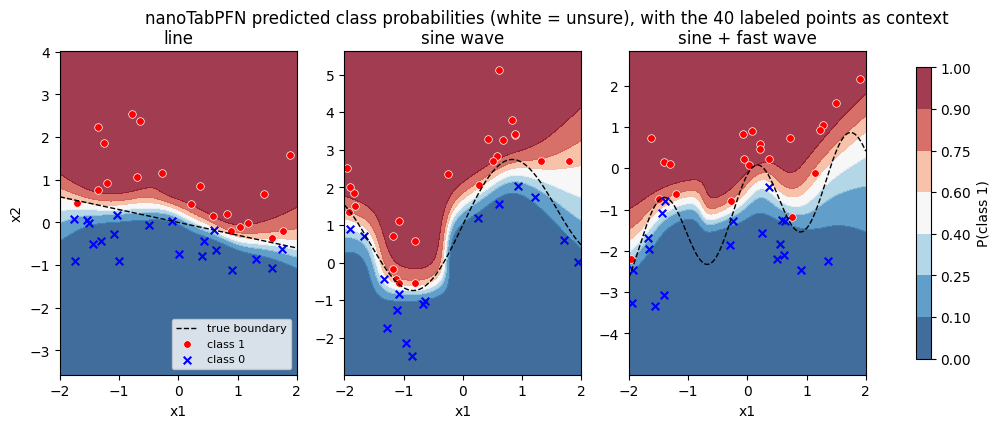

In [14]:
plot_predictions(small)

In [15]:
compare_with_baseline(
    {"small, lines prior": small_lines, "small, wave prior": small})

accuracy               line   sine wave   sine + fast wave   mean
-----------------------------------------------------------------
small, lines prior    0.955       0.685              0.760  0.800
small, wave prior     0.940       0.835              0.820  0.865
logistic regression   0.955       0.705              0.760  0.807
random forest         0.925       0.775              0.745  0.815


## 5. Scaling up

We now scale up by doubling three knobs: a wider embedding (48 → 96), more layers (2 → 3) and more training steps (750 → 2,500). This run takes a couple of minutes on a GPU or Apple Silicon.

In [ ]:
large = train(NanoTabPFN(emb=96, layers=3), num_steps=2500, lr=1e-3)

step  250 |  14.9s | loss  0.343 | test accuracy 0.877


### Evaluating the larger model

The large model now follows the wavy boundary. The white uncertainty band runs along the boundary and gets wider where labeled points of the two classes are far apart.

The model also outperforms logistic regression and random forests on this data.

In [ ]:
plot_predictions(large)

In [ ]:
compare_with_baseline(
    {"small, wave prior": small, "large, wave prior": large})

## Recap

In this lesson, you built and pretrained a miniature tabular foundation model (`NanoTabPFN`) from scratch:

- **Pretraining on a synthetic prior:** Tabular foundation models learn to generalize by pretraining on millions of synthetic tables generated on the fly from a prior distribution.
- **Two-way tabular attention:** By embedding each table cell and alternating attention across features (columns) and across datapoints (labeled context rows), the transformer processes entire tables in a single forward pass.
- **In-context learning via cross-entropy:** Training the network to predict held-out test rows from labeled context rows across many synthetic datasets teaches it to infer decision boundaries and calibrated uncertainty at inference time without weight updates.
- **Richer priors and scaling:** Expanding the expressiveness of the prior (from straight lines to waves) and scaling up model capacity and training steps directly improve in-context accuracy on complex, nonlinear datasets.